<a href="https://colab.research.google.com/github/Gayam-Deepthi/Cancer-Genomics/blob/main/SWYNEX_Task2_Data_Cleaning_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# SWYNEX Internship - Task 2
# Data Cleaning and Basic Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")



All libraries imported successfully!


In [4]:

# Load the three datasets

counts = pd.read_csv(
    "/GSE52778_raw_counts_GRCh38.p13_NCBI.tsv.gz",
    sep="\t"
)

fpkm = pd.read_csv(
    "/GSE52778_All_Sample_FPKM_Matrix.txt.gz",
    sep=r"\s+"
)

diff = pd.read_csv(
    "/GSE52778_Dex_vs_Untreated_gene_exp.diff.gz",
    sep="\t"
)

print("Raw counts:", counts.shape)
print("FPKM matrix:", fpkm.shape)
print("Differential expression:", diff.shape)



Raw counts: (39376, 17)
FPKM matrix: (23273, 41)
Differential expression: (23273, 14)


In [5]:

# STEP 3: Inspect the raw count dataset

print("First 5 rows:")
display(counts.head())

print("\nColumn names:")
print(counts.columns.tolist())

print("\nDataset information:")
counts.info()

print("\nStatistical summary:")
display(counts.describe())


First 5 rows:


,GeneID,GSM1275862,GSM1275863,GSM1275864,GSM1275865,GSM1275866,GSM1275867,GSM1275868,GSM1275869,GSM1275870,GSM1275871,GSM1275872,GSM1275873,GSM1275874,GSM1275875,GSM1275876,GSM1275877
0,100287102,6,8,8,3,5,10,11,7,6,8,4,10,2,1,2,2
1,653635,357,292,351,285,469,428,523,442,367,415,404,354,371,381,367,341
2,102466751,12,11,12,10,15,15,19,15,9,11,18,9,10,9,12,6
3,107985730,1,1,2,1,3,2,2,3,1,1,1,1,2,1,1,1
4,100302278,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,1



Column names:
['GeneID', 'GSM1275862', 'GSM1275863', 'GSM1275864', 'GSM1275865', 'GSM1275866', 'GSM1275867', 'GSM1275868', 'GSM1275869', 'GSM1275870', 'GSM1275871', 'GSM1275872', 'GSM1275873', 'GSM1275874', 'GSM1275875', 'GSM1275876', 'GSM1275877']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39376 entries, 0 to 39375
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   GeneID      39376 non-null  int64
 1   GSM1275862  39376 non-null  int64
 2   GSM1275863  39376 non-null  int64
 3   GSM1275864  39376 non-null  int64
 4   GSM1275865  39376 non-null  int64
 5   GSM1275866  39376 non-null  int64
 6   GSM1275867  39376 non-null  int64
 7   GSM1275868  39376 non-null  int64
 8   GSM1275869  39376 non-null  int64
 9   GSM1275870  39376 non-null  int64
 10  GSM1275871  39376 non-null  int64
 11  GSM1275872  39376 non-null  int64
 12  GSM1275873  39376 non-null  int64
 13  GSM1275874  39376 non-null  i

,GeneID,GSM1275862,GSM1275863,GSM1275864,GSM1275865,GSM1275866,GSM1275867,GSM1275868,GSM1275869,GSM1275870,GSM1275871,GSM1275872,GSM1275873,GSM1275874,GSM1275875,GSM1275876,GSM1275877
count,3.937600e+04,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000
mean,4.441428e+07,533.136352,487.560875,525.931075,511.910885,661.697557,992.054526,941.528952,684.133990,698.837947,807.780628,716.455252,726.968687,794.511708,950.620657,664.949487,730.666396
std,5.159676e+07,4245.015868,3575.798792,4155.086184,3766.822887,6054.278209,8355.080947,8123.125744,6228.541827,6053.665205,6518.156909,5707.441045,5963.234626,7130.548049,7917.117661,5866.287658,6162.835957
min,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.878250e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.764545e+05,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,1.053697e+08,199.000000,169.000000,198.000000,177.000000,234.000000,317.250000,301.000000,236.000000,249.000000,263.000000,238.000000,260.000000,291.000000,312.000000,247.000000,246.000000
max,1.156947e+08,259289.000000,213560.000000,239167.000000,226535.000000,511182.000000,692766.000000,671926.000000,501733.000000,395978.000000,397171.000000,347152.000000,362602.000000,612322.000000,646892.000000,511305.000000,552194.000000


In [6]:

# STEP 4: Data quality assessment

print("Missing values:")
print(counts.isnull().sum().sum())

print("\nDuplicate rows:")
print(counts.duplicated().sum())

print("\nDuplicate gene IDs:")
print(counts["GeneID"].duplicated().sum())

# Identify all-zero genes
sample_cols = counts.columns.drop("GeneID")

zero_genes = (counts[sample_cols].sum(axis=1) == 0).sum()

print("\nGenes with zero counts in all samples:", zero_genes)


Missing values:
0

Duplicate rows:
0

Duplicate gene IDs:
0

Genes with zero counts in all samples: 9267


In [7]:

# STEP 5: DATA CLEANING

# Create a separate copy of the original dataset
clean_counts = counts.copy()

# Remove genes having zero counts in all samples
sample_cols = clean_counts.columns.drop("GeneID")

clean_counts = clean_counts[
    clean_counts[sample_cols].sum(axis=1) > 0
].copy()

# Verify cleaned dataset
print("Original dataset shape:", counts.shape)
print("Cleaned dataset shape:", clean_counts.shape)

print("Genes removed:",
      counts.shape[0] - clean_counts.shape[0])

# Check whether all-zero genes remain
print("Remaining all-zero genes:",
      (clean_counts[sample_cols].sum(axis=1) == 0).sum())


Original dataset shape: (39376, 17)
Cleaned dataset shape: (30109, 17)
Genes removed: 9267
Remaining all-zero genes: 0


In [8]:

# STEP 6: EXPORT CLEANED DATASET

clean_counts.to_csv(
    "/content/GSE52778_Cleaned_Raw_Counts.csv",
    index=False
)

print("Cleaned dataset successfully saved!")


Cleaned dataset successfully saved!


In [9]:

from google.colab import files

files.download(
    "/content/GSE52778_Cleaned_Raw_Counts.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

# STEP 7: DESCRIPTIVE STATISTICS

sample_statistics = counts[sample_cols].describe()

display(sample_statistics)


,GSM1275862,GSM1275863,GSM1275864,GSM1275865,GSM1275866,GSM1275867,GSM1275868,GSM1275869,GSM1275870,GSM1275871,GSM1275872,GSM1275873,GSM1275874,GSM1275875,GSM1275876,GSM1275877
count,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000,39376.000000
mean,533.136352,487.560875,525.931075,511.910885,661.697557,992.054526,941.528952,684.133990,698.837947,807.780628,716.455252,726.968687,794.511708,950.620657,664.949487,730.666396
std,4245.015868,3575.798792,4155.086184,3766.822887,6054.278209,8355.080947,8123.125744,6228.541827,6053.665205,6518.156909,5707.441045,5963.234626,7130.548049,7917.117661,5866.287658,6162.835957
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,199.000000,169.000000,198.000000,177.000000,234.000000,317.250000,301.000000,236.000000,249.000000,263.000000,238.000000,260.000000,291.000000,312.000000,247.000000,246.000000
max,259289.000000,213560.000000,239167.000000,226535.000000,511182.000000,692766.000000,671926.000000,501733.000000,395978.000000,397171.000000,347152.000000,362602.000000,612322.000000,646892.000000,511305.000000,552194.000000


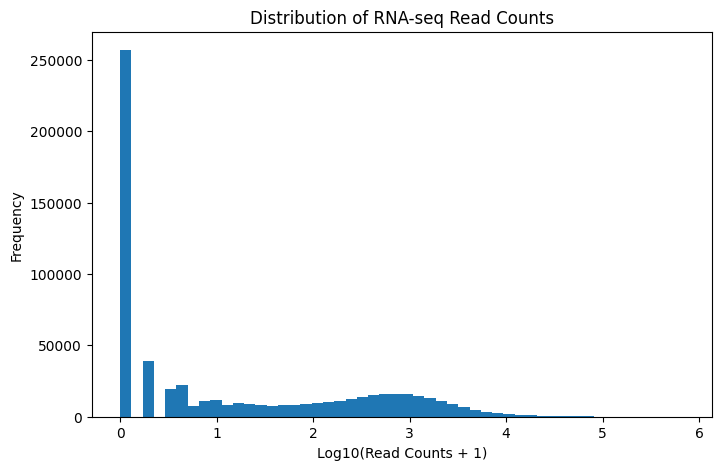

In [15]:

# STEP 8: HISTOGRAM

plt.figure(figsize=(8,5))

plt.hist(
    np.log10(counts[sample_cols].values.flatten() + 1),
    bins=50
)

plt.xlabel("Log10(Read Counts + 1)")
plt.ylabel("Frequency")
plt.title("Distribution of RNA-seq Read Counts")
plt.savefig(
    "/content/SWYNEX_Results/graph_name.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


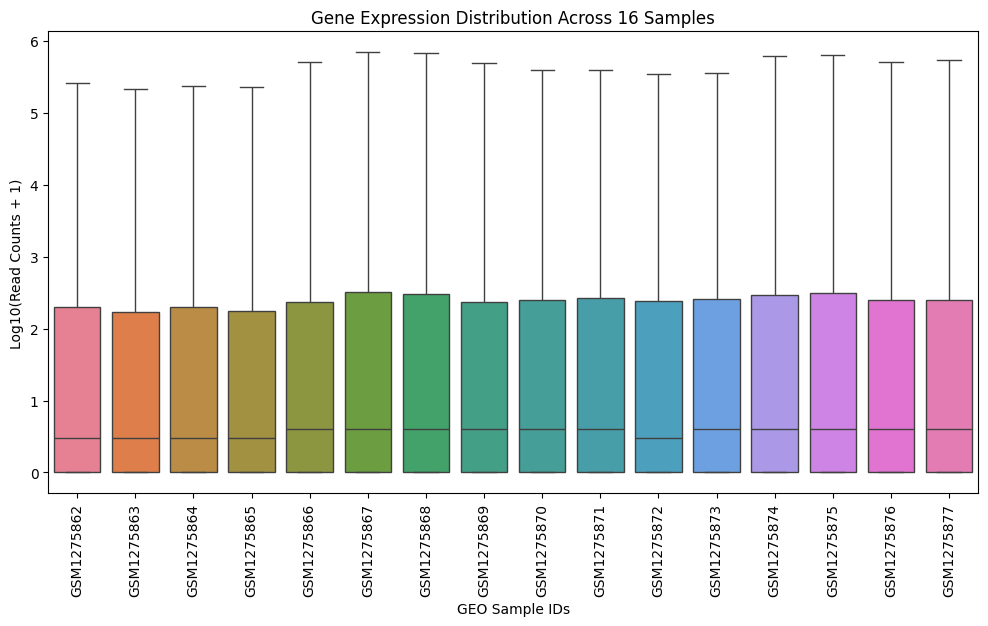

In [16]:

# STEP 9: BOXPLOT

plt.figure(figsize=(12,6))

sns.boxplot(data=np.log10(counts[sample_cols] + 1))

plt.xticks(rotation=90)
plt.xlabel("GEO Sample IDs")
plt.ylabel("Log10(Read Counts + 1)")
plt.title("Gene Expression Distribution Across 16 Samples")
plt.savefig(
    "/content/SWYNEX_Results/graph_name.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


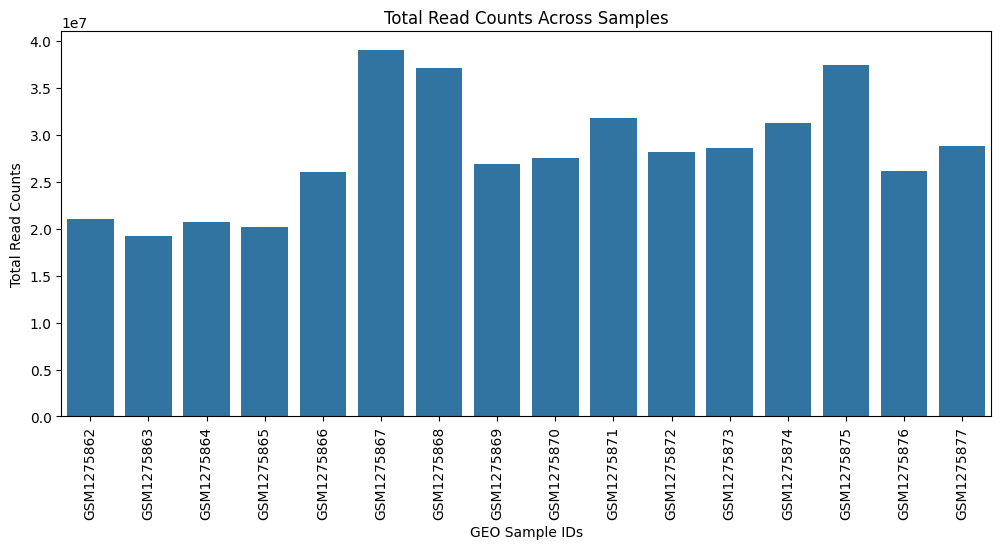

In [17]:

# STEP 10: SAMPLE-WISE TOTAL COUNTS

total_counts = counts[sample_cols].sum()

plt.figure(figsize=(12,5))

sns.barplot(x=total_counts.index, y=total_counts.values)

plt.xticks(rotation=90)
plt.xlabel("GEO Sample IDs")
plt.ylabel("Total Read Counts")
plt.title("Total Read Counts Across Samples")
plt.savefig(
    "/content/SWYNEX_Results/graph_name.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



In [14]:

# STEP 11: CREATE A FOLDER FOR RESULTS

import os

os.makedirs("/content/SWYNEX_Results", exist_ok=True)

print("Results folder created!")


Results folder created!


In [18]:

# STEP 12: FINAL DATASET SUMMARY

summary = {
    "Original genes": counts.shape[0],
    "Number of samples": len(sample_cols),
    "Genes removed": counts.shape[0] - clean_counts.shape[0],
    "Genes after cleaning": clean_counts.shape[0],
    "Missing values": counts.isnull().sum().sum(),
    "Duplicate rows": counts.duplicated().sum(),
    "Duplicate gene IDs": counts["GeneID"].duplicated().sum(),
    "Remaining zero-count genes":
        (clean_counts[sample_cols].sum(axis=1) == 0).sum()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Parameter", "Result"]
)

display(summary_df)

summary_df.to_csv(
    "/content/SWYNEX_Results/final_dataset_summary.csv",
    index=False
)


,Parameter,Result
0,Original genes,39376
1,Number of samples,16
2,Genes removed,9267
3,Genes after cleaning,30109
4,Missing values,0
5,Duplicate rows,0
6,Duplicate gene IDs,0
7,Remaining zero-count genes,0


In [19]:

import os

print("Files generated in SWYNEX_Results:")

for file in os.listdir("/content/SWYNEX_Results"):
    print(file)


Files generated in SWYNEX_Results:
final_dataset_summary.csv
graph_name.png


In [20]:

import shutil

shutil.make_archive(
    "/content/SWYNEX_Results",
    "zip",
    "/content",
    "SWYNEX_Results"
)

print("Results folder compressed successfully!")


Results folder compressed successfully!


In [21]:

from google.colab import files

files.download("/content/SWYNEX_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>